In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/drive/MyDrive/Projects/Diabetes Classification/diabetes_binary_health_indicators_BRFSS2015.csv')
pd.set_option('display.max_columns', None)

In [3]:
df.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


Diabetes_binary : you have diabetes (0,1)

HighBP : Adults who have been told they have high blood pressure by a doctor, nurse, or other health professional (0,1)

HighChol : Have you EVER been told by a doctor, nurse or other health professional that your blood cholesterol is high? (0,1)

CholCheck : Cholesterol check within past five years (0,1)

BMI : Body Mass Index (BMI)

Smoker : Have you smoked at least 100 cigarettes in your entire life? [Note: 5 packs = 100 cigarettes] (0,1)

Stroke : (Ever told) you had a stroke. (0,1)

HeartDiseaseorAttack : Respondents that have ever reported having coronary heart disease (CHD) or myocardial infarction (MI) (0,1)

PhysActivity : Adults who reported doing physical activity or exercise during the past 30 days other than their regular job (0,1)

Fruits : Consume Fruit 1 or more times per day (0,1)

Veggies : Consume Vegetables 1 or more times per day (0,1)

HvyAlcoholConsump : Heavy drinkers (adult men having more than 14 drinks per week and adult women having more than 7 drinks per week)(0,1)

AnyHealthcare : Do you have any kind of health care coverage, including health insurance, prepaid plans such as HMOs, or government plans such as Medicare, or Indian Health Service? (0,1)

NoDocbcCost : Was there a time in the past 12 months when you needed to see a doctor but could not because of cost? (0,1)

GenHlth : Would you say that in general your health is: rate (1 ~ 5)

MentHlth : Now thinking about your mental health, which includes stress, depression, and problems with emotions, for how many days during the past 30 days was your mental health not good? (0 ~ 30)

PhysHlth : Now thinking about your physical health, which includes physical illness and injury, for how many days during the past 30 days was your physical health not good? (0 ~ 30)

DiffWalk : Do you have serious difficulty walking or climbing stairs? (0,1)

Sex : Indicate sex of respondent (0,1) (Female or Male)

Age : Fourteen-level age category (1 ~ 14)

Education : What is the highest grade or year of school you completed? (1 ~ 6)

Income : Is your annual household income from all sources: (If respondent refuses at any income level, code "Refused.") (1 ~ 8)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  

# Data Preprocessing

In [5]:
df["Diabetes_binary"] = df["Diabetes_binary"].astype(int)
df["HighBP"] = df["HighBP"].astype(int)
df["HighChol"] = df["HighChol"].astype(int)
df["CholCheck"] = df["CholCheck"].astype(int)
df["BMI"] = df["BMI"].astype(int)
df["Smoker"] = df["Smoker"].astype(int)
df["Stroke"] = df["Stroke"].astype(int)
df["HeartDiseaseorAttack"] = df["HeartDiseaseorAttack"].astype(int)
df["PhysActivity"] = df["PhysActivity"].astype(int)
df["Fruits"] = df["Fruits"].astype(int)
df["Veggies"] = df["Veggies"].astype(int)
df["HvyAlcoholConsump"] = df["HvyAlcoholConsump"].astype(int)
df["AnyHealthcare"] = df["AnyHealthcare"].astype(int)
df["NoDocbcCost"] = df["NoDocbcCost"].astype(int)
df["GenHlth"] = df["GenHlth"].astype(int)
df["MentHlth"] = df["MentHlth"].astype(int)
df["PhysHlth"] = df["PhysHlth"].astype(int)
df["DiffWalk"] = df["DiffWalk"].astype(int)
df["Sex"] = df["Sex"].astype(int)
df["Age"] = df["Age"].astype(int)
df["Education"] = df["Education"].astype(int)
df["Income"] =df["Income"].astype(int)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   Diabetes_binary       253680 non-null  int64
 1   HighBP                253680 non-null  int64
 2   HighChol              253680 non-null  int64
 3   CholCheck             253680 non-null  int64
 4   BMI                   253680 non-null  int64
 5   Smoker                253680 non-null  int64
 6   Stroke                253680 non-null  int64
 7   HeartDiseaseorAttack  253680 non-null  int64
 8   PhysActivity          253680 non-null  int64
 9   Fruits                253680 non-null  int64
 10  Veggies               253680 non-null  int64
 11  HvyAlcoholConsump     253680 non-null  int64
 12  AnyHealthcare         253680 non-null  int64
 13  NoDocbcCost           253680 non-null  int64
 14  GenHlth               253680 non-null  int64
 15  MentHlth              253680 non-n

In [7]:
df.isnull().sum()

,0
Diabetes_binary,0
HighBP,0
HighChol,0
CholCheck,0
BMI,0
Smoker,0
Stroke,0
HeartDiseaseorAttack,0
PhysActivity,0
Fruits,0


No Missing Values

In [8]:
df.duplicated().sum()

np.int64(24206)

There are 24206 duplicated columns so dropping them

In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df.nunique()

,0
Diabetes_binary,2
HighBP,2
HighChol,2
CholCheck,2
BMI,84
Smoker,2
Stroke,2
HeartDiseaseorAttack,2
PhysActivity,2
Fruits,2


In [11]:
df['Diabetes_binary'].value_counts(normalize=True)

,proportion
Diabetes_binary,
0,0.847055
1,0.152945


In [12]:
for col in df:
    print(f"Column: {col}")
    print(df[col].unique())

Column: Diabetes_binary
[0 1]
Column: HighBP
[1 0]
Column: HighChol
[1 0]
Column: CholCheck
[1 0]
Column: BMI
[40 25 28 27 24 30 34 26 33 21 23 22 38 32 37 31 29 20 35 45 39 19 47 18
 36 43 55 49 42 17 16 41 44 50 59 48 52 46 54 57 53 14 15 51 58 63 61 56
 74 62 64 66 73 85 60 67 65 70 82 79 92 68 72 88 96 13 81 71 75 12 77 69
 76 87 89 84 95 98 91 86 83 80 90 78]
Column: Smoker
[1 0]
Column: Stroke
[0 1]
Column: HeartDiseaseorAttack
[0 1]
Column: PhysActivity
[0 1]
Column: Fruits
[0 1]
Column: Veggies
[1 0]
Column: HvyAlcoholConsump
[0 1]
Column: AnyHealthcare
[1 0]
Column: NoDocbcCost
[0 1]
Column: GenHlth
[5 3 2 4 1]
Column: MentHlth
[18  0 30  3  5 15 10  6 20  2 25  1  4  7  8 21 14 26 29 16 28 11 12 24
 17 13 27 19 22  9 23]
Column: PhysHlth
[15  0 30  2 14 28  7 20  3 10  1  5 17  4 19  6 12 25 27 21 22  8 29 24
  9 16 18 23 13 26 11]
Column: DiffWalk
[1 0]
Column: Sex
[0 1]
Column: Age
[ 9  7 11 10  8 13  4  6  2 12  5  1  3]
Column: Education
[4 6 3 5 2 1]
Column: Income
[3 1 

Lets Encode the data for better understanding (as there are some ordinal data)

In [13]:
df_eda = df.copy()   # keep df numeric for modeling

yes_no = {0: "No", 1: "Yes"}

maps = {
    "Diabetes_binary": {0: "No Diabetes", 1: "Diabetes/Prediabetes"},
    "HighBP": {0: "No High BP", 1: "High BP"},
    "HighChol": {0: "No High Cholesterol", 1: "High Cholesterol"},
    "CholCheck": {0: "No Chol Check in 5 Yrs", 1: "Chol Check in 5 Yrs"},
    "Sex": {0: "Female", 1: "Male"},
    "GenHlth": {1: "Excellent", 2: "Very Good", 3: "Good", 4: "Fair", 5: "Poor"},
    "Age": {1: "18-24", 2: "25-29", 3: "30-34", 4: "35-39", 5: "40-44",
            6: "45-49", 7: "50-54", 8: "55-59", 9: "60-64", 10: "65-69",
            11: "70-74", 12: "75-79", 13: "80+"},
    "Education": {1: "Never/Kindergarten", 2: "Elementary (1-8)", 3: "Some High School",
                  4: "High School Grad", 5: "Some College", 6: "College Grad"},
    "Income": {1: "<$10k", 2: "$10-15k", 3: "$15-20k", 4: "$20-25k",
               5: "$25-35k", 6: "$35-50k", 7: "$50-75k", 8: "$75k+"},
}
for col in ["Smoker", "Stroke", "HeartDiseaseorAttack", "PhysActivity", "Fruits",
            "Veggies", "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk"]:
    maps[col] = yes_no

for col, m in maps.items():
    df_eda[col] = df_eda[col].map(m)

### Ordinal Feature Encoding (EDA only)

`Age`, `GenHlth`, `Education`, and `Income` have a natural order (e.g., 18-24 < 25-29 < ... < 80+), so they are converted to **ordered categoricals** in `df_eda`. This keeps their categories in a meaningful order in plots, tables, and `groupby` results instead of sorting alphabetically.

This step is for visualization and exploration only. The modeling pipeline uses the original numeric version of the data (`df`), where the integer codes already preserve the order of the categories.

In [14]:
for col in ["Age", "GenHlth", "Education", "Income"]:
    df_eda[col] = pd.Categorical(df_eda[col], categories=list(maps[col].values()), ordered=True)

In [15]:
df_eda.info()

<class 'pandas.core.frame.DataFrame'>
Index: 229474 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype   
---  ------                --------------   -----   
 0   Diabetes_binary       229474 non-null  object  
 1   HighBP                229474 non-null  object  
 2   HighChol              229474 non-null  object  
 3   CholCheck             229474 non-null  object  
 4   BMI                   229474 non-null  int64   
 5   Smoker                229474 non-null  object  
 6   Stroke                229474 non-null  object  
 7   HeartDiseaseorAttack  229474 non-null  object  
 8   PhysActivity          229474 non-null  object  
 9   Fruits                229474 non-null  object  
 10  Veggies               229474 non-null  object  
 11  HvyAlcoholConsump     229474 non-null  object  
 12  AnyHealthcare         229474 non-null  object  
 13  NoDocbcCost           229474 non-null  object  
 14  GenHlth               229474 non-null  ca

<Axes: xlabel='count', ylabel='Diabetes_binary'>

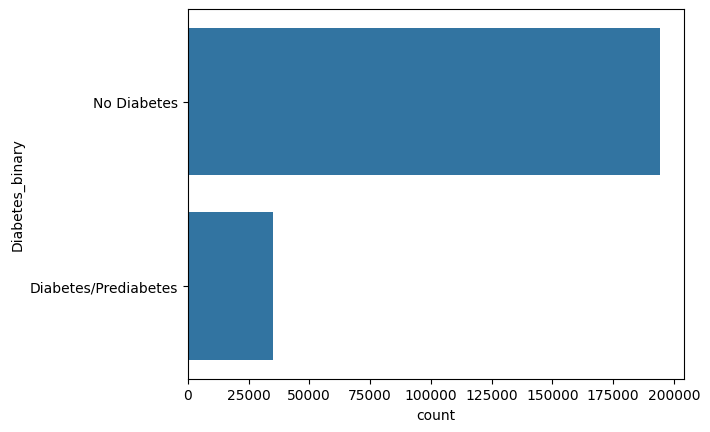

In [26]:
sns.countplot(df_eda['Diabetes_binary'])

array([[<Axes: title={'center': 'Diabetes_binary'}>,
        <Axes: title={'center': 'HighBP'}>,
        <Axes: title={'center': 'HighChol'}>,
        <Axes: title={'center': 'CholCheck'}>,
        <Axes: title={'center': 'BMI'}>],
       [<Axes: title={'center': 'Smoker'}>,
        <Axes: title={'center': 'Stroke'}>,
        <Axes: title={'center': 'HeartDiseaseorAttack'}>,
        <Axes: title={'center': 'PhysActivity'}>,
        <Axes: title={'center': 'Fruits'}>],
       [<Axes: title={'center': 'Veggies'}>,
        <Axes: title={'center': 'HvyAlcoholConsump'}>,
        <Axes: title={'center': 'AnyHealthcare'}>,
        <Axes: title={'center': 'NoDocbcCost'}>,
        <Axes: title={'center': 'GenHlth'}>],
       [<Axes: title={'center': 'MentHlth'}>,
        <Axes: title={'center': 'PhysHlth'}>,
        <Axes: title={'center': 'DiffWalk'}>,
        <Axes: title={'center': 'Sex'}>, <Axes: title={'center': 'Age'}>],
       [<Axes: title={'center': 'Education'}>,
        <Axes: title=

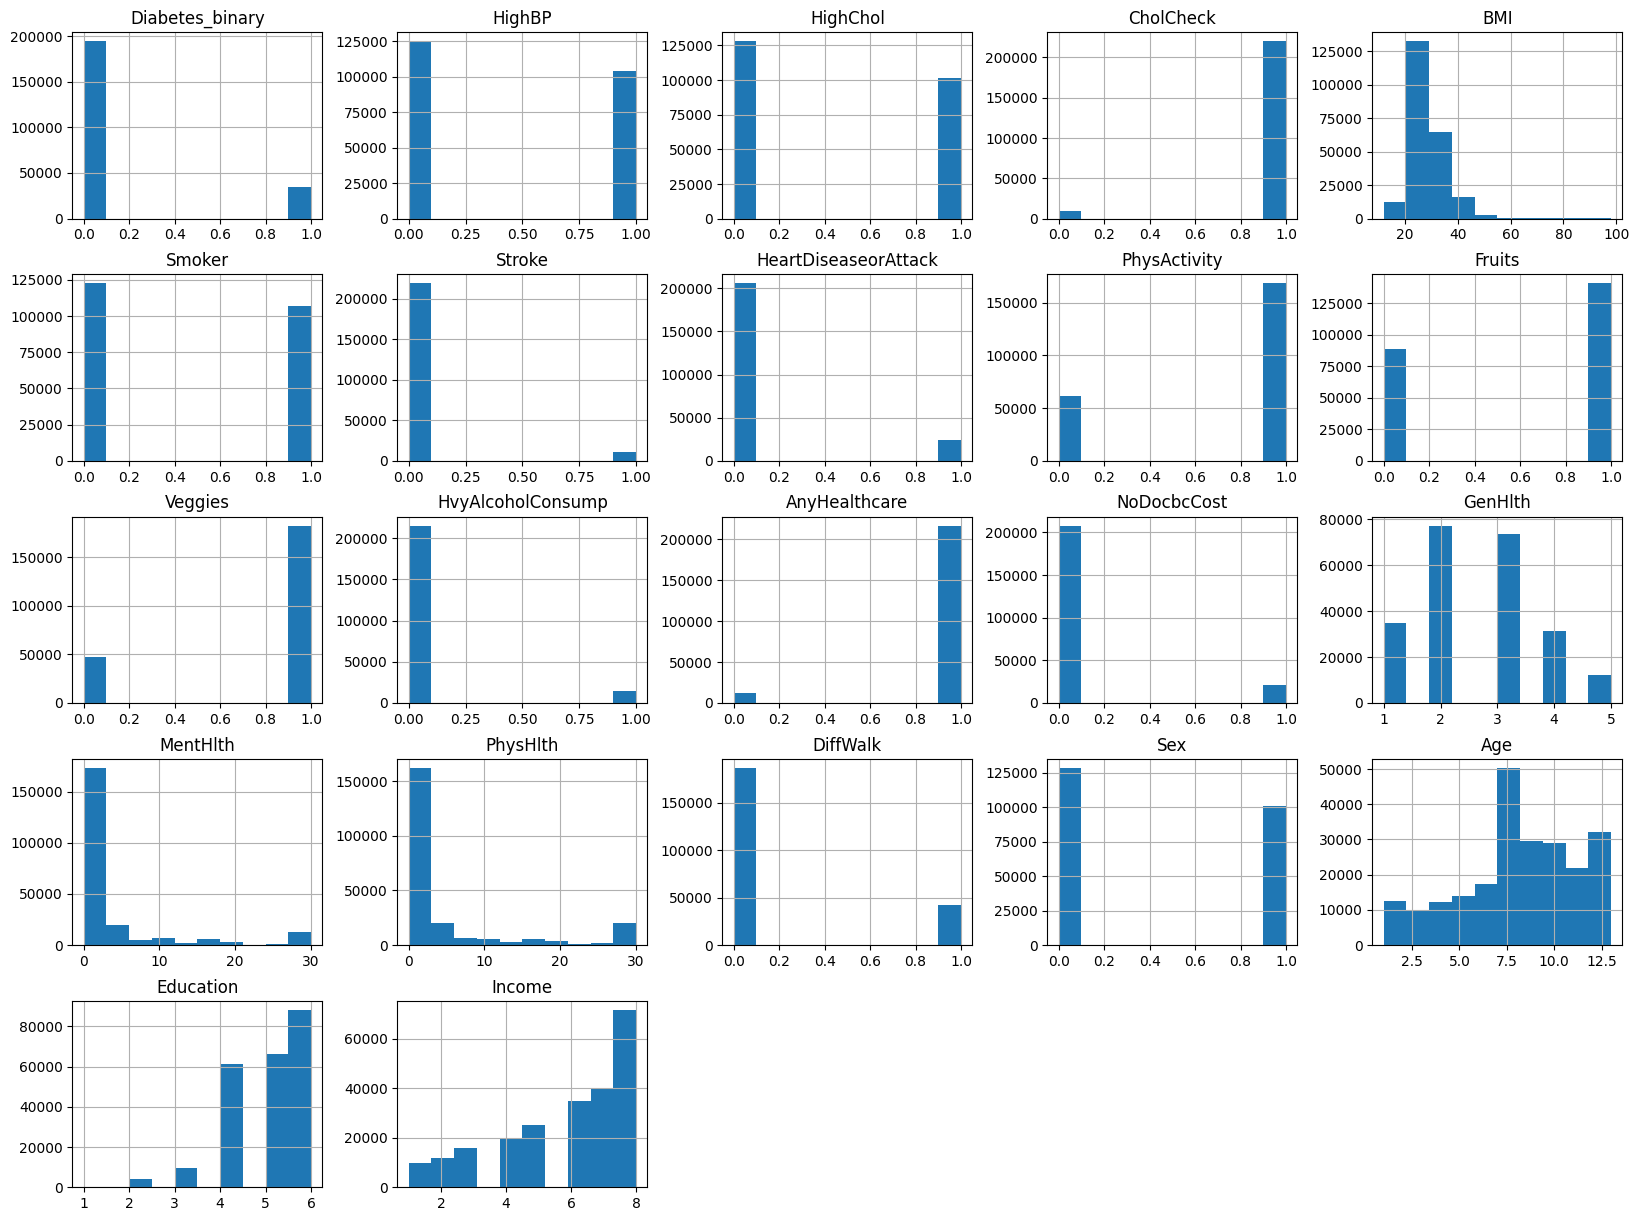

In [17]:
df.hist(figsize=(20, 15))

In [18]:
cols_binary = ['HighBP', 'HighChol', 'CholCheck','Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk']

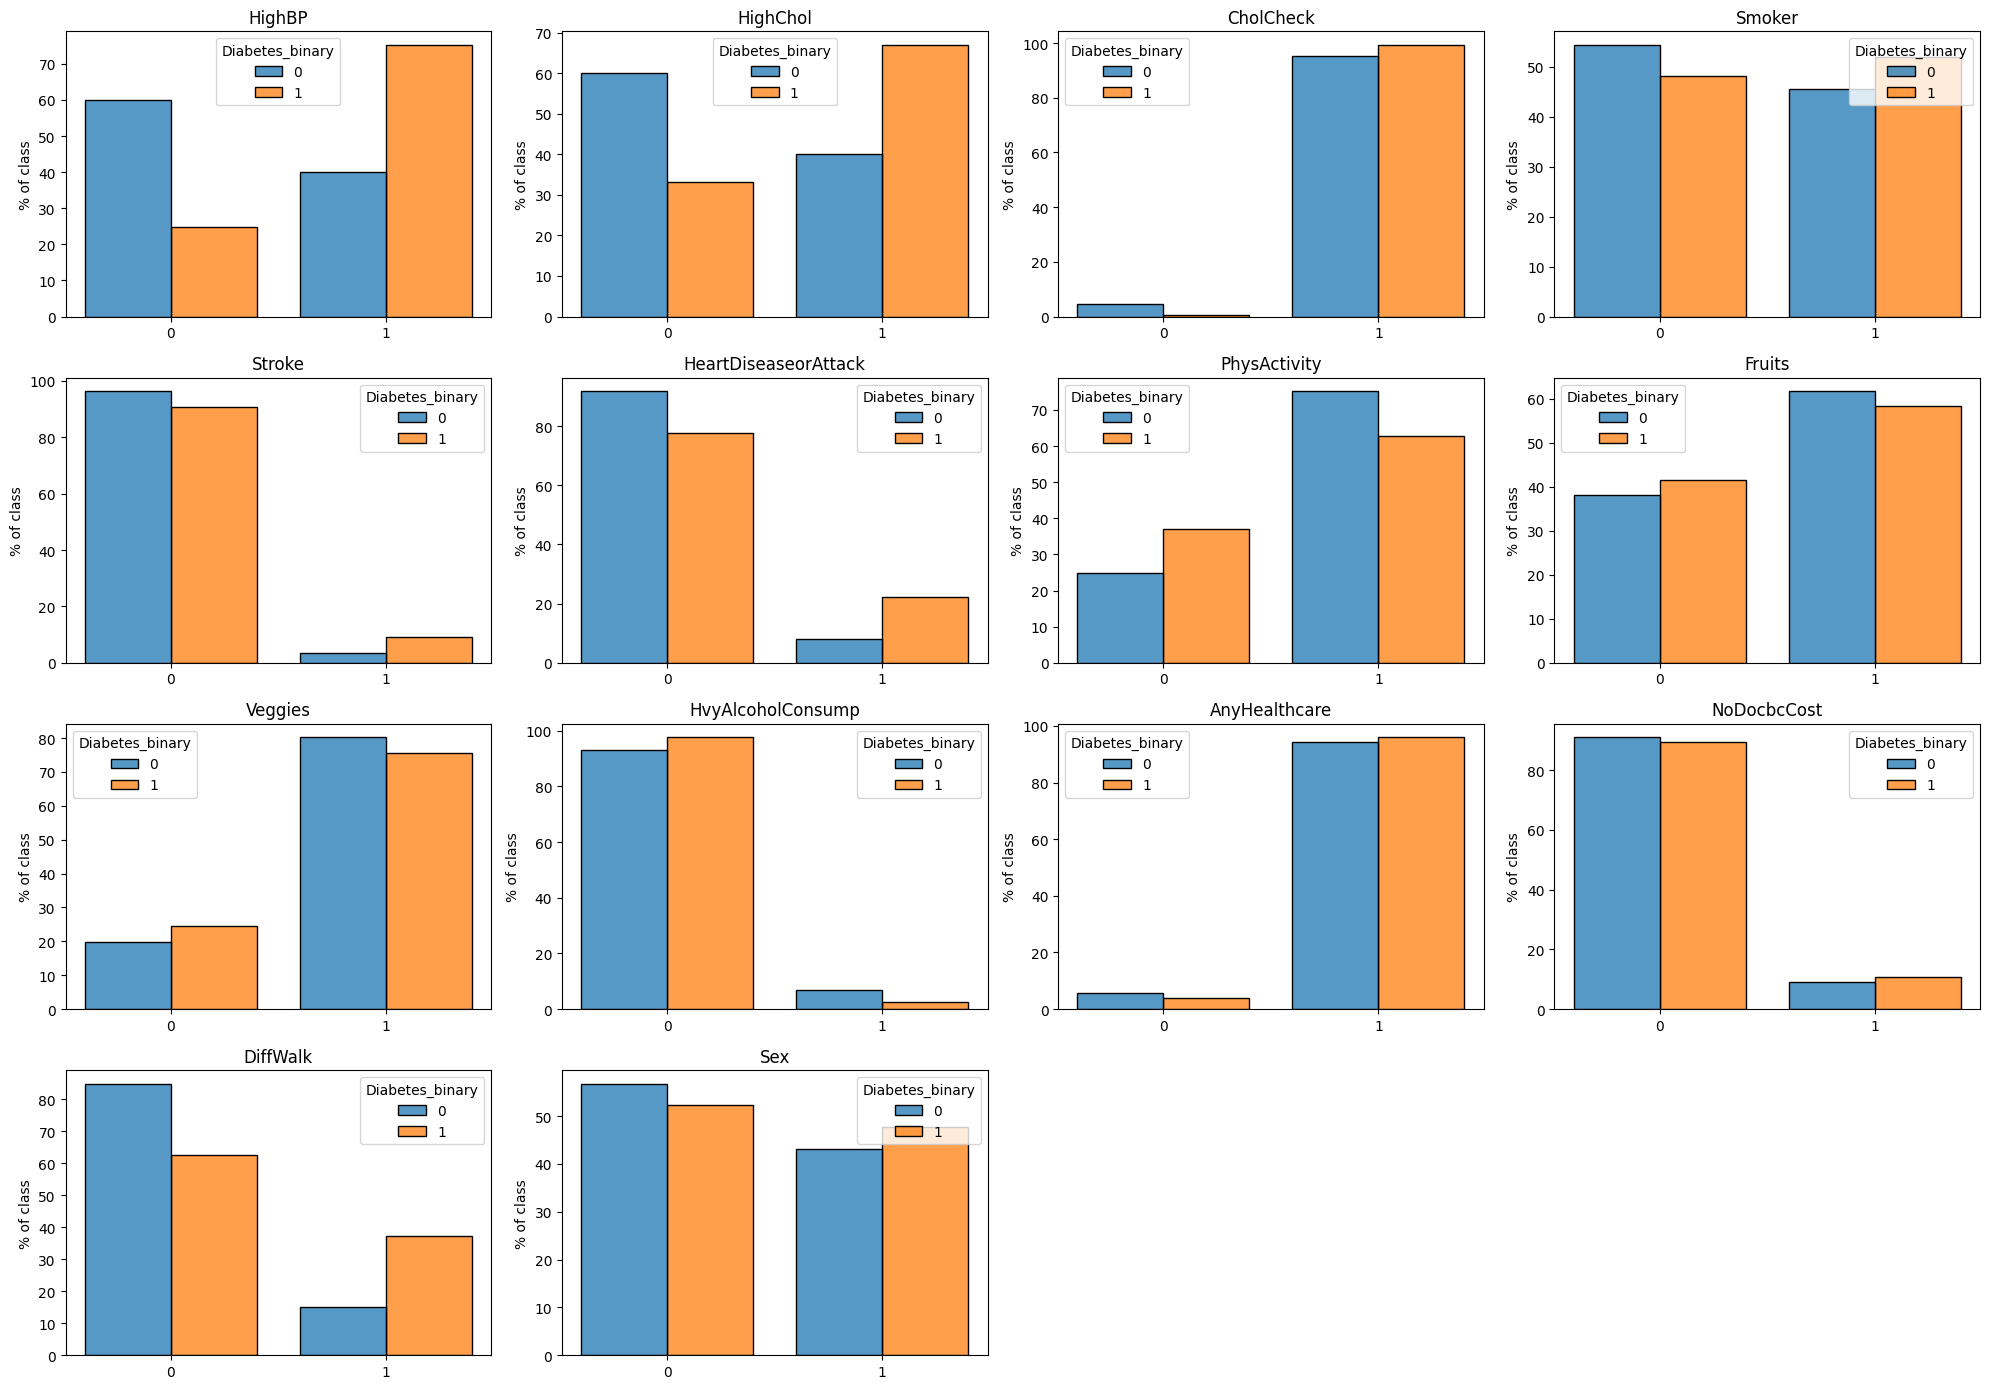

In [19]:
binary_cols = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke',
               'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
               'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']

fig, axes = plt.subplots(4, 4, figsize=(20, 14))
for ax, col in zip(axes.ravel(), binary_cols):
    sns.histplot(data=df, x=col, hue="Diabetes_binary",
                 discrete=True, multiple="dodge",
                 stat="percent", common_norm=False,   # % within each class
                 shrink=0.8, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("% of class")
for ax in axes.ravel()[len(binary_cols):]:
    ax.axis("off")                                     # hide the empty subplots
plt.tight_layout()

### Observations: Binary Features vs. Diabetes Status

Each bar shows the percentage of that class (0 = no diabetes, 1 = diabetes/prediabetes) falling into the feature's 0 or 1 group. Bars are normalized within each class, so the imbalance does not distort the comparison.

**Strongest separators (large gap between classes)**
- **HighBP:** about 75% of the diabetes group has high blood pressure, compared with about 40% of the non-diabetes group.
- **HighChol:** about 67% vs. 40%, so high cholesterol is also much more common among people with diabetes.
- **DiffWalk:** about 37% of the diabetes group has difficulty walking, vs. about 15% of the non-diabetes group.
- **HeartDiseaseorAttack:** about 22% vs. 8%, a nearly threefold difference.
- **Stroke:** about 9% vs. 4%. Both rates are low, but it is still more than double.

**Moderate separators**
- **PhysActivity:** about 63% of the diabetes group is physically active, vs. about 75% of the non-diabetes group, so inactivity is more common with diabetes.
- **Smoker:** slightly higher in the diabetes group (about 52% vs. 45%).
- **Veggies and Fruits:** slightly lower intake in the diabetes group (Veggies about 75% vs. 80%, Fruits about 58% vs. 62%).
- **Sex:** the diabetes group has a slightly higher share of males (about 48% vs. 43%).

**Weak or near-identical features**
- **CholCheck, AnyHealthcare, NoDocbcCost:** both classes are almost identical. About 95% or more of respondents in each class have had a cholesterol check or have healthcare coverage, so these features carry little signal.

**Counterintuitive result**
- **HvyAlcoholConsump:** heavy drinking is *less* common in the diabetes group (about 2-3% vs. about 7%). This probably reflects people with diabetes being advised to reduce alcohol, or healthier-drinker effects in self-reported data. It should not be read as alcohol being protective.

**Takeaways**
- Cardiovascular and metabolic risk indicators (HighBP, HighChol, HeartDiseaseorAttack, DiffWalk) are the clearest markers of diabetes status in this dataset.
- Lifestyle features (PhysActivity, Smoker, Veggies, Fruits) show smaller differences, and healthcare-access features show almost none.
- These are associations in self-reported survey data, not evidence of causation. Feature importance from the model will help confirm which variables matter most for prediction.

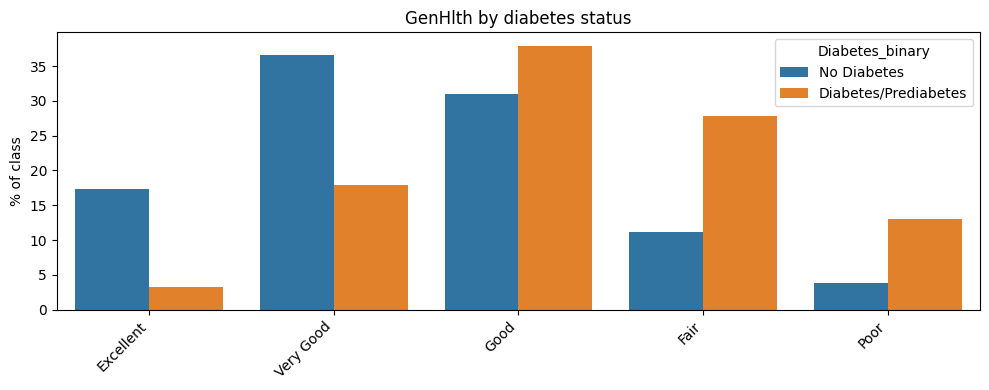

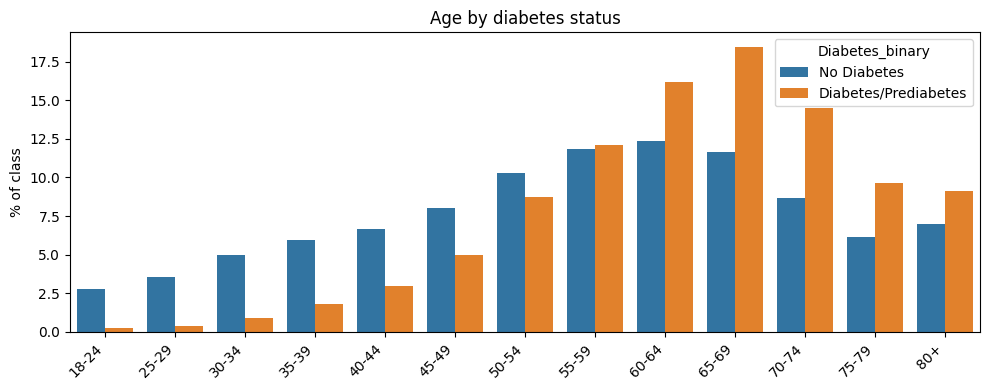

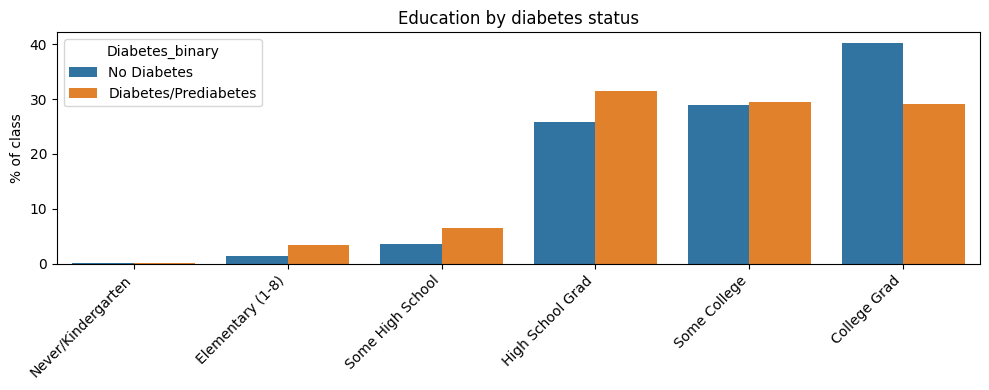

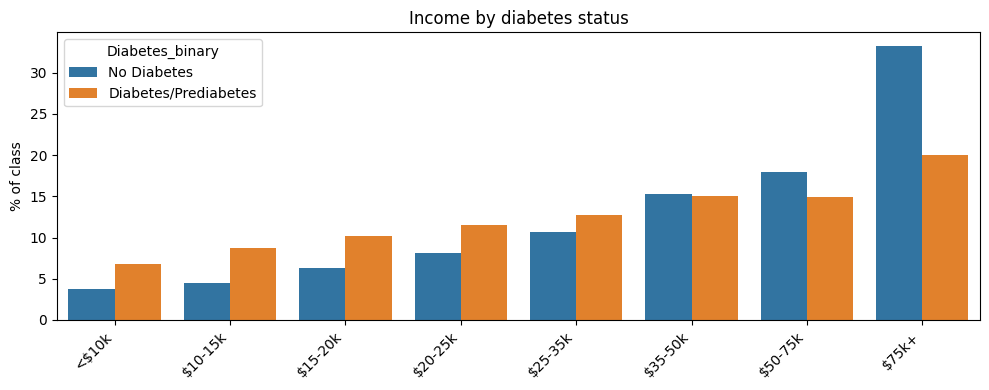

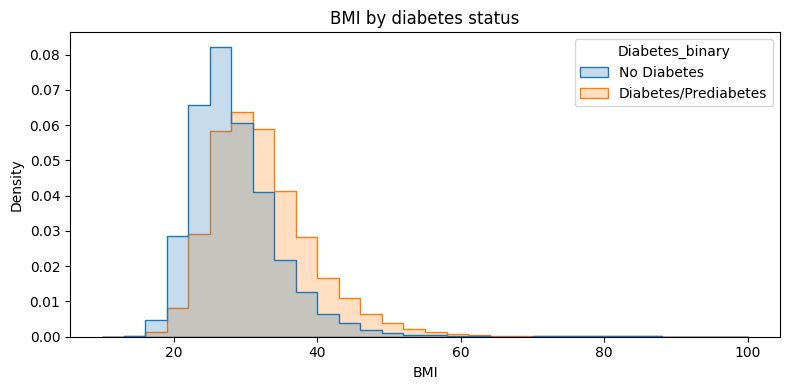

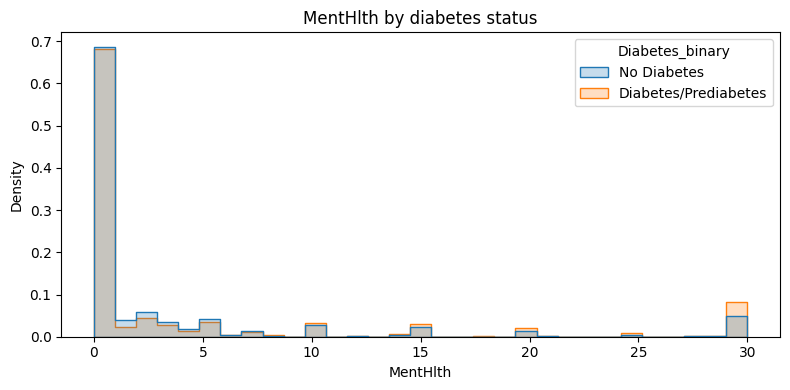

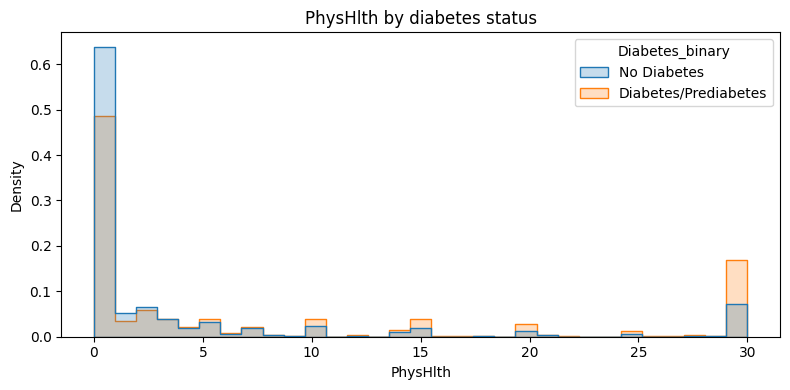

In [20]:
target = "Diabetes_binary"
hue_order = list(maps[target].values())          # ["No Diabetes", "Diabetes/Prediabetes"]

# --- Ordinal / discrete columns (ordered categories, % within each class) ---
for col in ["GenHlth", "Age", "Education", "Income"]:
    order = list(maps[col].values())             # dict order = low -> high
    pct = (df_eda.groupby(target, observed=True)[col]
                 .value_counts(normalize=True)
                 .mul(100).rename("percent").reset_index())

    plt.figure(figsize=(10, 4))
    sns.barplot(data=pct, x=col, y="percent", hue=target,
                order=order, hue_order=hue_order)
    plt.title(f"{col} by diabetes status")
    plt.ylabel("% of class")
    plt.xlabel("")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# --- Continuous / skewed columns (numeric df, so the axis is naturally ordered) ---
hue_labels = df[target].map(maps[target])        # readable legend, no change to df

for col in ["BMI", "MentHlth", "PhysHlth"]:
    plt.figure(figsize=(8, 4))
    sns.histplot(x=df[col], hue=hue_labels, hue_order=hue_order,
                 stat="density", common_norm=False, element="step",
                 bins=30 if col == "BMI" else 31,
                 binrange=(10, 100) if col == "BMI" else (0, 30))
    plt.title(f"{col} by diabetes status")
    plt.tight_layout()
    plt.show()

### Observations: Ordinal and Continuous Features vs. Diabetes Status

Bars and curves are normalized within each class (0 = no diabetes, 1 = diabetes/prediabetes), so the class imbalance does not distort the comparison.

**General Health (GenHlth)**
- Self-rated health is strongly worse in the diabetes group. Only about 3% rate their health "Excellent" (vs. about 17% without diabetes), and about 18% say "Very Good" (vs. about 36%).
- "Fair" (about 28% vs. 11%) and "Poor" (about 13% vs. 4%) are far more common with diabetes. This is one of the clearest separators in the dataset.

**Age**
- Diabetes cases are concentrated in older groups. Below age 50, the non-diabetes group is larger in every band (for example, about 3% vs. 0.2% at 18-24).
- The two groups are about equal at 55-59, and from 60 onward the diabetes group dominates. The peak is at 65-69 (about 18% of the diabetes group vs. 12% of the non-diabetes group).
- Age is a strong predictor, with risk rising steadily through the 60s and 70s.

**Education**
- Lower education is over-represented among people with diabetes: Elementary (about 3.5% vs. 1.5%), Some High School (about 6.5% vs. 3.7%), and High School Grad (about 31% vs. 26%).
- College graduates are under-represented in the diabetes group (about 29% vs. 40%). "Some College" is about equal.
- The "Never/Kindergarten" group is tiny (under 1%), so it is not reliable on its own.

**Income**
- There is a clear income gradient. Every income band below $35k  has a larger share of the diabetes group, with the gap widest at the lowest incomes (about 6.8% vs. 3.8% under $10k).
- The groups are equal at $35-50k. In the top band ($75k+), only about 20% of the diabetes group falls there, vs. about 33%

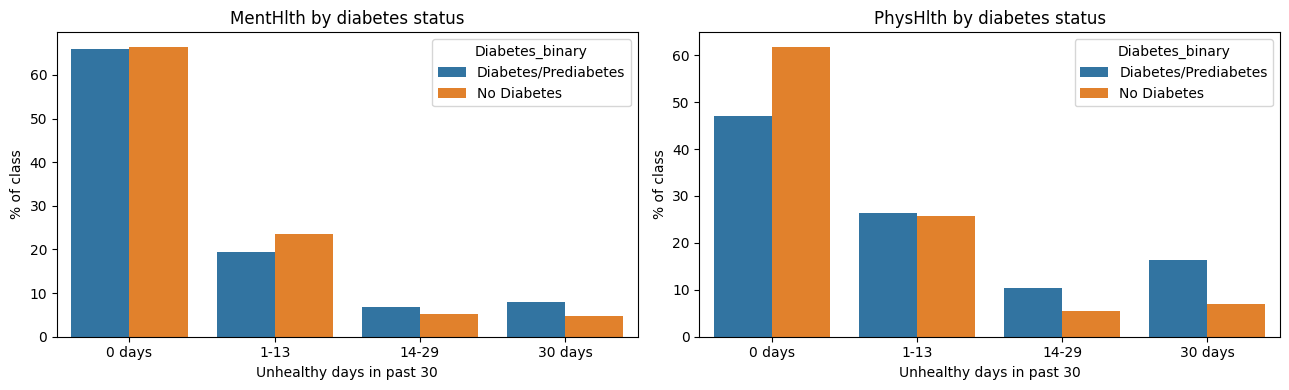

In [27]:
ue_labels = df["Diabetes_binary"].map({0: "No Diabetes", 1: "Diabetes/Prediabetes"})
bins   = [-1, 0, 13, 29, 30]
labels = ["0 days", "1-13", "14-29", "30 days"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["MentHlth", "PhysHlth"]):
    bin_col = pd.cut(df[col], bins=bins, labels=labels, ordered=True)   # ordered categorical
    pct = (pd.crosstab(hue_labels, bin_col, normalize="index") * 100).reset_index()
    pct = pct.melt(id_vars="Diabetes_binary", var_name="bin", value_name="percent")
    sns.barplot(data=pct, x="bin", y="percent", hue="Diabetes_binary",
                order=labels, ax=ax)
    ax.set_title(f"{col} by diabetes status")
    ax.set_xlabel("Unhealthy days in past 30")
    ax.set_ylabel("% of class")
plt.tight_layout()
plt.show()

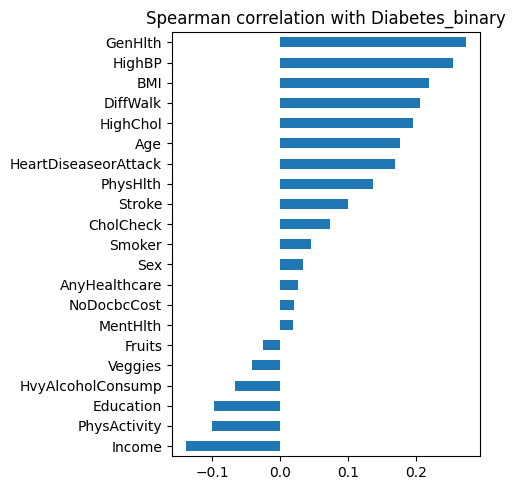

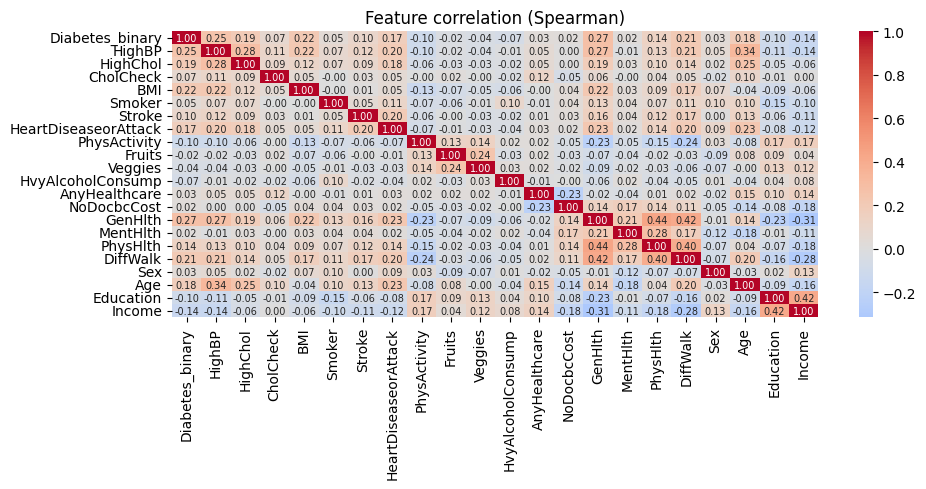

GenHlth    PhysHlth    0.438629
           DiffWalk    0.418918
Education  Income      0.417106
PhysHlth   DiffWalk    0.404468
dtype: float64


In [28]:
corr = df.corr(method="spearman")      # numeric df; Spearman suits ordinal/count/binary columns

# 1. Correlation with the target
target_corr = corr["Diabetes_binary"].drop("Diabetes_binary").sort_values()
target_corr.plot.barh(figsize=(5, 5), title="Spearman correlation with Diabetes_binary")
plt.tight_layout(); plt.show()

# 2. Full heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Feature correlation (Spearman)")
plt.tight_layout(); plt.show()

# 3. Pairs of features that are strongly correlated with each other
pairs = (corr.abs().where(~np.tril(np.ones(corr.shape, dtype=bool)))
             .stack().sort_values(ascending=False))
print(pairs[pairs > 0.4])

### Observations: Correlation Analysis (Spearman)

Spearman correlation was used because most features are binary, ordinal, or discrete counts. For `GenHlth`, higher codes mean poorer health (1 = Excellent, 5 = Poor), so a positive correlation means worse self-rated health goes with diabetes.

**Correlation with the target (Diabetes_binary)**
- **Strongest positive:** GenHlth (0.27), HighBP (0.25), BMI (0.22), DiffWalk (0.21), HighChol (0.19), Age (0.18), HeartDiseaseorAttack (0.17), and PhysHlth (0.14).
- **Strongest negative:** Income (-0.14), PhysActivity (-0.10), Education (-0.10), and HvyAlcoholConsump (-0.07). Higher income, education, and activity go with lower diabetes rates.
- **Near zero:** MentHlth, NoDocbcCost, AnyHealthcare, Sex, Smoker, Fruits, and Veggies (all within ±0.05). Individually they carry little linear signal.
- All correlations are modest, with the maximum at about 0.27. No single feature predicts diabetes on its own, which suggests the model will rely on a combination of features.

**Correlation between features**
- The most related pairs are GenHlth with PhysHlth (0.44), GenHlth with DiffWalk (0.42), PhysHlth with DiffWalk (0.40), and Education with Income (0.42). These form a group of health-status variables and a group of socioeconomic variables.
- Other notable pairs are HighBP with Age (0.34), GenHlth with Income (-0.31), DiffWalk with Income (-0.28), and HighBP with HighChol (0.28).
- No pair exceeds about 0.45, so multicollinearity is not a concern and no features need to be dropped for that reason.

**Takeaways**
- Health status (GenHlth, DiffWalk, PhysHlth), cardiovascular risk (HighBP, HighChol, HeartDiseaseorAttack), BMI, and age are the most associated with diabetes, which matches the earlier plots.
- Socioeconomic factors show a weaker but consistent negative relationship.
- Correlation only captures monotonic relationships and cannot detect interactions, so model-based feature importance will be used to confirm which features matter for prediction.

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier

y = df["Diabetes_binary"].astype(int)
X = df.drop(columns="Diabetes_binary")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Logistic Regression

In [30]:
from sklearn.linear_model import LogisticRegression

lg = LogisticRegression(max_iter = 1500,class_weight='balanced')
lg.fit(X_train , y_train)

LogisticRegression(class_weight='balanced', max_iter=1500)

In [31]:
# make predictions on test set
y_pred=lg.predict(X_test)

print('Training set score: {:.4f}'.format(lg.score(X_train, y_train)))

print('Test set score: {:.4f}'.format(lg.score(X_test, y_test)))

Training set score: 0.7174
Test set score: 0.7142


In [32]:
from sklearn.metrics import classification_report

matrix = classification_report(y_test,y_pred )
print(matrix)

              precision    recall  f1-score   support

           0       0.94      0.71      0.81     38876
           1       0.32      0.76      0.45      7019

    accuracy                           0.71     45895
   macro avg       0.63      0.73      0.63     45895
weighted avg       0.85      0.71      0.75     45895



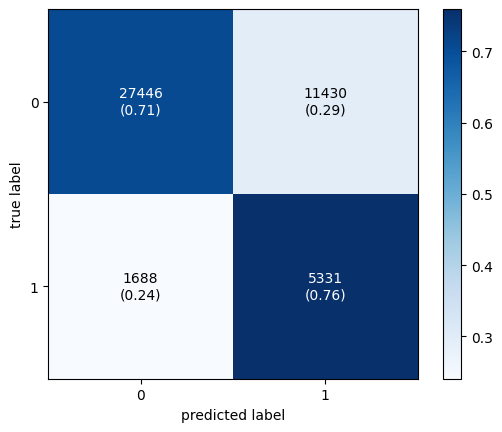

In [35]:
from sklearn.metrics import confusion_matrix
from mlxtend.plotting import plot_confusion_matrix

cm1 = confusion_matrix(y_test,y_pred)
plot_confusion_matrix(conf_mat=cm1,show_absolute=True,
                                show_normed=True,
                                colorbar=True)
plt.show()

In [41]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(max_depth = 12, class_weight='balanced')
dt.fit(X_train , y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=12)

In [42]:
# make predictions on test set
y_pred=dt.predict(X_test)

print('Training set score: {:.4f}'.format(dt.score(X_train, y_train)))

print('Test set score: {:.4f}'.format(dt.score(X_test, y_test)))

Training set score: 0.7243
Test set score: 0.6972


In [43]:
matrix = classification_report(y_test,y_pred )
print(matrix)

              precision    recall  f1-score   support

           0       0.94      0.69      0.79     38876
           1       0.30      0.75      0.43      7019

    accuracy                           0.70     45895
   macro avg       0.62      0.72      0.61     45895
weighted avg       0.84      0.70      0.74     45895



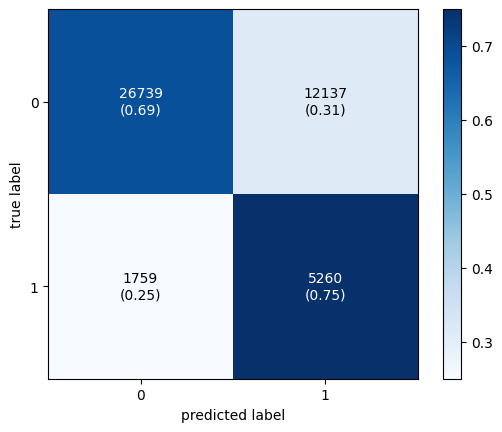

In [44]:
# calculating and plotting the confusion matrix
cm1 = confusion_matrix(y_test,y_pred)
plot_confusion_matrix(conf_mat=cm1,show_absolute=True,
                                show_normed=True,
                                colorbar=True)
plt.show()

In [45]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=200, max_depth=12, class_weight='balanced_subsample', n_jobs=-1)
rf.fit(X_train , y_train)

RandomForestClassifier(class_weight='balanced_subsample', max_depth=12,
                       n_estimators=200, n_jobs=-1)

In [65]:
# make predictions on test set
y_pred = rf.predict(X_test)

print('Training set score: {:.4f}'.format(rf.score(X_train, y_train)))

print('Test set score: {:.4f}'.format(rf.score(X_test, y_test)))

Training set score: 0.7525
Test set score: 0.7339


In [47]:
matrix = classification_report(y_test,y_pred )
print(matrix)

              precision    recall  f1-score   support

           0       0.94      0.73      0.82     38876
           1       0.33      0.74      0.46      7019

    accuracy                           0.73     45895
   macro avg       0.64      0.74      0.64     45895
weighted avg       0.85      0.73      0.77     45895



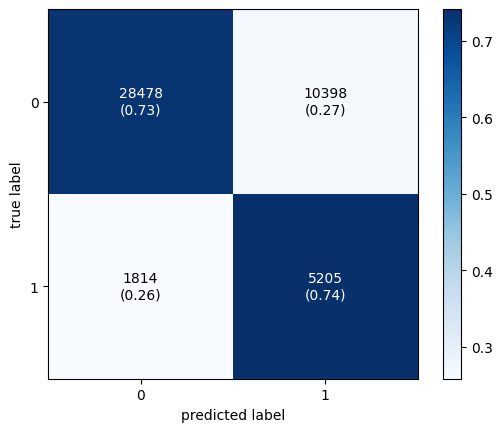

In [48]:
# calculating and plotting the confusion matrix
cm1 = confusion_matrix(y_test,y_pred)
plot_confusion_matrix(conf_mat=cm1,show_absolute=True,
                                show_normed=True,
                                colorbar=True)
plt.show()

In [51]:
from xgboost import XGBClassifier
spw = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.08,
                             subsample=0.8, colsample_bytree=0.8,
                             scale_pos_weight=spw , eval_metric="aucpr",
                             n_jobs=-1, random_state=42)

xgb.fit(X_train , y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='aucpr', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.08, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=-1, num_parallel_tree=None, ...)

In [53]:
# make predictions on test set
y_pred=xgb.predict(X_test)

print('Training set score: {:.4f}'.format(xgb.score(X_train, y_train)))

print('Test set score: {:.4f}'.format(xgb.score(X_test, y_test)))

Training set score: 0.7120
Test set score: 0.7077


In [54]:
matrix = classification_report(y_test,y_pred )
print(matrix)

              precision    recall  f1-score   support

           0       0.95      0.69      0.80     38876
           1       0.32      0.79      0.45      7019

    accuracy                           0.71     45895
   macro avg       0.63      0.74      0.63     45895
weighted avg       0.85      0.71      0.75     45895



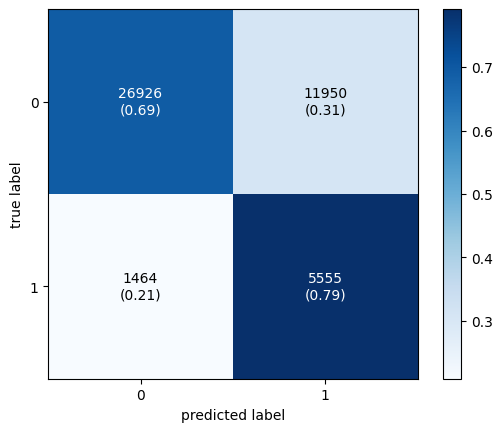

In [55]:
# calculating and plotting the confusion matrix
cm1 = confusion_matrix(y_test,y_pred)
plot_confusion_matrix(conf_mat=cm1,show_absolute=True,
                                show_normed=True,
                                colorbar=True)
plt.show()

Drop in ROC-AUC when each feature is shuffled:
 GenHlth                 0.0492
BMI                     0.0402
Age                     0.0367
HighBP                  0.0173
HighChol                0.0126
CholCheck               0.0060
HvyAlcoholConsump       0.0054
Sex                     0.0040
Income                  0.0036
MentHlth                0.0024
HeartDiseaseorAttack    0.0023
DiffWalk                0.0015
PhysHlth                0.0015
Education               0.0009
Stroke                  0.0006
Smoker                  0.0005
Veggies                 0.0003
AnyHealthcare           0.0003
Fruits                  0.0003
PhysActivity            0.0002
NoDocbcCost             0.0001
dtype: float64


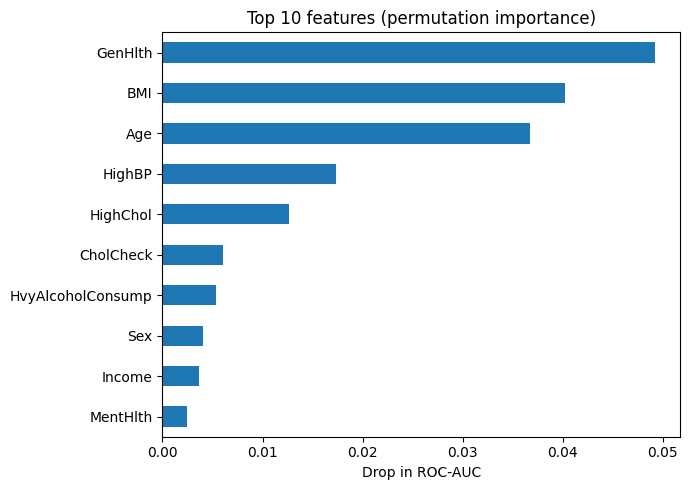

 k  ROC-AUC  PR-AUC                                                               features
 3    0.792   0.394                                                      GenHlth, BMI, Age
 5    0.809   0.426                                    GenHlth, BMI, Age, HighBP, HighChol
 8    0.815   0.434 GenHlth, BMI, Age, HighBP, HighChol, CholCheck, HvyAlcoholConsump, Sex
10    0.816   0.437                                                                       
15    0.819   0.443                                                                       
21    0.819   0.445                                                                       


In [63]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

spw = (ytr == 0).sum() / (ytr == 1).sum()
def xgb():
    return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5, subsample=0.8,
                         colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="aucpr",
                         n_jobs=2, random_state=42)

# ---- Q2: which features matter? (permutation importance on VALIDATION data) ----
full = xgb().fit(Xtr, ytr)
perm = permutation_importance(full, Xval, yval, scoring="roc_auc",
                              n_repeats=5, random_state=42, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=Xtr.columns).sort_values(ascending=False)
print("Drop in ROC-AUC when each feature is shuffled:\n", imp.round(4))

imp.head(10).sort_values().plot.barh(figsize=(7, 5), title="Top 10 features (permutation importance)")
plt.xlabel("Drop in ROC-AUC"); plt.tight_layout(); plt.show()

# ---- Q3: do the top-k features predict almost as well as all of them? ----
rows = []
for k in [3, 5, 8, 10, 15, len(imp)]:
    cols = list(imp.index[:k])                       # ranking came from train/val only
    m = xgb().fit(Xtr[cols], ytr)
    p = m.predict_proba(Xte[cols])[:, 1]
    rows.append({"k": k, "ROC-AUC": roc_auc_score(yte, p),
                 "PR-AUC": average_precision_score(yte, p),
                 "features": ", ".join(cols) if k <= 8 else ""})
print(pd.DataFrame(rows).round(3).to_string(index=False))

*Findings**
- **General health, BMI and age are the strongest predictors.** Each one is worth about 0.04-0.05 AUC, more than twice the next feature.
- **High blood pressure and high cholesterol** come next, and the five features together carry most of the model's predictive signal.
- **Importance drops sharply after the top 5.** Features ranked 6-10 each contribute less than 0.01 AUC.


=== Classification report: Top 5 features ===
              precision    recall  f1-score   support

           0      0.945     0.682     0.792     38876
           1      0.307     0.781     0.441      7019

    accuracy                          0.697     45895
   macro avg      0.626     0.731     0.617     45895
weighted avg      0.848     0.697     0.739     45895



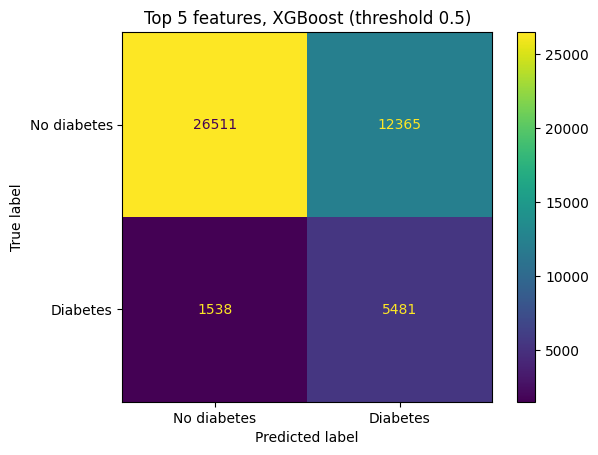

          model  n_features  ROC-AUC  PR-AUC  Precision  Recall    F1
 Top 5 features           5     0.81   0.430      0.307   0.781 0.441
All 21 features          21     0.82   0.448      0.317   0.791 0.453


In [66]:
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, roc_auc_score, average_precision_score,
                             precision_recall_fscore_support, ConfusionMatrixDisplay)

top5 = ["GenHlth", "BMI", "Age", "HighBP", "HighChol"]
spw = (y_train == 0).sum() / (y_train == 1).sum()

def make_xgb():
    return XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.08, subsample=0.8,
                         colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="aucpr",
                         n_jobs=-1, random_state=42)

rows = []
for name, cols in [("Top 5 features", top5), ("All 21 features", list(X_train.columns))]:
    model = make_xgb().fit(X_train[cols], y_train)
    proba = model.predict_proba(X_test[cols])[:, 1]
    pred = (proba >= 0.5).astype(int)
    P, R, F, _ = precision_recall_fscore_support(y_test, pred, pos_label=1, average="binary")
    rows.append({"model": name, "n_features": len(cols),
                 "ROC-AUC": roc_auc_score(y_test, proba),
                 "PR-AUC": average_precision_score(y_test, proba),
                 "Precision": P, "Recall": R, "F1": F})
    if name == "Top 5 features":
        print("=== Classification report: Top 5 features ===")
        print(classification_report(y_test, pred, digits=3))
        ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No diabetes", "Diabetes"])
        plt.title("Top 5 features, XGBoost (threshold 0.5)"); plt.show()

print(pd.DataFrame(rows).round(3).to_string(index=False))